     GWO ROBOT PATH PLANNING CONFIGURATION     
Press [ENTER] at any prompt to use the default value.

Enter Start X coordinate [Default: 10.0]: 
Enter Start Y coordinate [Default: 10.0]: 
Enter Goal X coordinate [Default: 90.0]: 
Enter Goal Y coordinate [Default: 90.0]: 
Enter Population Size (N wolves) [Default: 30]: 
Enter Maximum Iterations (T) [Default: 100]: 
Enter Number of Intermediate Waypoints [Default: 5]: 

[Processing] Optimizing robot path via GWO...

             GWO PLANNER EXECUTION            
Optimal Path Cost Value:  123.06
Status: Path generated safely avoiding obstacles.


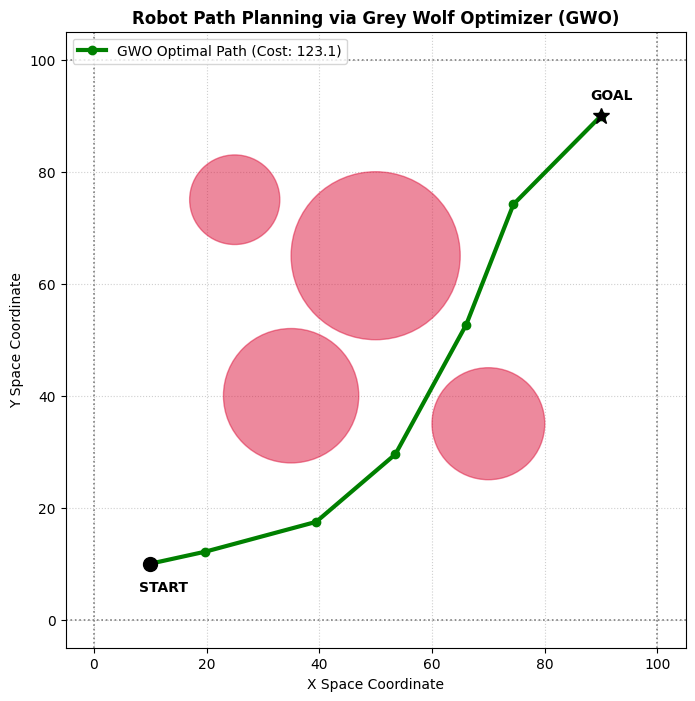

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# 1. USER INPUT WIZARD INTERFACE
# =============================================================================
print("="*50)
print("     GWO ROBOT PATH PLANNING CONFIGURATION     ")
print("="*50)
print("Press [ENTER] at any prompt to use the default value.\n")

def get_input(prompt, default_val, expected_type=float):
    user_val = input(f"{prompt} [Default: {default_val}]: ").strip()
    if not user_val:
        return default_val
    try:
        return expected_type(user_val)
    except ValueError:
        print(f"⚠️ Invalid format. Using default value: {default_val}")
        return default_val

# Mission Coordinates
start_x = get_input("Enter Start X coordinate", 10.0)
start_y = get_input("Enter Start Y coordinate", 10.0)
START = np.array([start_x, start_y])

goal_x = get_input("Enter Goal X coordinate", 90.0)
goal_y = get_input("Enter Goal Y coordinate", 90.0)
GOAL = np.array([goal_x, goal_y])

# Workspace Boundaries [Min, Max]
MAP_MIN, MAP_MAX = 0.0, 100.0

# Optimization Hyperparameters
POP_SIZE = get_input("Enter Population Size (N wolves)", 30, expected_type=int)
MAX_ITER = get_input("Enter Maximum Iterations (T)", 100, expected_type=int)
M_WAYPOINTS = get_input("Enter Number of Intermediate Waypoints", 5, expected_type=int)

# Static Environment Obstacles [X_center, Y_center, Radius]
OBSTACLES = [
    [35.0, 40.0, 12.0],
    [50.0, 65.0, 15.0],
    [70.0, 35.0, 10.0],
    [25.0, 75.0, 8.0]
]

# Evaluation Matrix Multipliers
W_LENGTH = 1.0
W_COLLISION = 1000.0  # High penalty forces paths out of threat circles
W_SMOOTHNESS = 5.0

# =============================================================================
# 2. FITNESS ENGINE (Robotic Path Evaluation)
# =============================================================================
def check_segment_collision(p1, p2, obstacles):
    """Calculates vector intersections across obstacle bounds."""
    collisions = 0
    v = p2 - p1
    v_len_sq = np.dot(v, v)
    if v_len_sq == 0:
        return 0
    for obs in obstacles:
        center = np.array([obs[0], obs[1]])
        radius = obs[2]
        w = center - p1
        t = np.clip(np.dot(w, v) / v_len_sq, 0.0, 1.0)
        closest_point = p1 + t * v
        if np.linalg.norm(center - closest_point) < radius:
            collisions += 1
    return collisions

def calculate_fitness(waypoints):
    """Computes total multi-objective path score (Minimization problem)."""
    full_path = np.vstack([START, waypoints, GOAL])
    n_points = len(full_path)

    path_length = 0.0
    collision_count = 0
    smoothness_cost = 0.0

    for i in range(n_points - 1):
        p1, p2 = full_path[i], full_path[i+1]

        # 1. Path Length Objective
        path_length += np.linalg.norm(p2 - p1)

        # 2. Safety Objective
        collision_count += check_segment_collision(p1, p2, OBSTACLES)

        # 3. Kinematic Smoothness Objective (Turn angles)
        if i < n_points - 2:
            p3 = full_path[i+2]
            v1, v2 = p2 - p1, p3 - p2
            mag1, mag2 = np.linalg.norm(v1), np.linalg.norm(v2)
            if mag1 > 0 and mag2 > 0:
                cos_theta = np.clip(np.dot(v1, v2) / (mag1 * mag2), -1.0, 1.0)
                smoothness_cost += np.arccos(cos_theta) ** 2

    return (W_LENGTH * path_length) + (W_COLLISION * collision_count) + (W_SMOOTHNESS * smoothness_cost)

# =============================================================================
# 3. GREY WOLF OPTIMIZER CORE LOOP
# =============================================================================
# Initialize the wolf pack along the line-of-sight vector with localized scatter noise
wolves = np.zeros((POP_SIZE, M_WAYPOINTS, 2))
for i in range(POP_SIZE):
    for j in range(M_WAYPOINTS):
        fraction = (j + 1) / (M_WAYPOINTS + 1)
        base_point = START + fraction * (GOAL - START)
        wolves[i, j] = base_point + np.random.uniform(-25, 25, size=2)
        wolves[i, j] = np.clip(wolves[i, j], MAP_MIN, MAP_MAX)

# Initialize hunting hierarchy elements
X_alpha = np.zeros((M_WAYPOINTS, 2))
X_beta  = np.zeros((M_WAYPOINTS, 2))
X_delta = np.zeros((M_WAYPOINTS, 2))

f_alpha, f_beta, f_delta = float('inf'), float('inf'), float('inf')

print("\n[Processing] Optimizing robot path via GWO...")

for t in range(MAX_ITER):
    # Step A: Evaluate fitness and rank leaders
    for i in range(POP_SIZE):
        fit = calculate_fitness(wolves[i])

        if fit < f_alpha:
            f_delta, X_delta = f_beta, X_delta.copy()
            f_beta, X_beta = f_alpha, X_beta.copy()
            f_alpha, X_alpha = fit, wolves[i].copy()
        elif fit < f_beta:
            f_delta, X_delta = f_beta, X_delta.copy()
            f_beta = fit; X_beta = wolves[i].copy()
        elif fit < f_delta:
            f_delta = fit; X_delta = wolves[i].copy()

    # Step B: Linear decay parameter a (decreases from 2 to 0)
    a = 2.0 - 2.0 * (t / MAX_ITER)

    # Step C: Pack coordinate position adjustment
    for i in range(POP_SIZE):
        for j in range(M_WAYPOINTS):

            # Encircling under Alpha direction
            r1, r2 = np.random.rand(2), np.random.rand(2)
            A1, C1 = 2 * a * r1 - a, 2 * r2
            D_alpha = np.abs(C1 * X_alpha[j] - wolves[i, j])
            X1 = X_alpha[j] - A1 * D_alpha

            # Encircling under Beta direction
            r1, r2 = np.random.rand(2), np.random.rand(2)
            A2, C2 = 2 * a * r1 - a, 2 * r2
            D_beta = np.abs(C2 * X_beta[j] - wolves[i, j])
            X2 = X_beta[j] - A2 * D_beta

            # Encircling under Delta direction
            r1, r2 = np.random.rand(2), np.random.rand(2)
            A3, C3 = 2 * a * r1 - a, 2 * r2
            D_delta = np.abs(C3 * X_delta[j] - wolves[i, j])
            X3 = X_delta[j] - A3 * D_delta

            # Move wolf based on collective pack knowledge
            wolves[i, j] = (X1 + X2 + X3) / 3.0

        # Constrain path positions strictly within workspace coordinates
        wolves[i] = np.clip(wolves[i], MAP_MIN, MAP_MAX)

print("\n" + "="*45)
print("             GWO PLANNER EXECUTION            ")
print("="*45)
print(f"Optimal Path Cost Value:  {f_alpha:.2f}")
print("Status: Path generated safely avoiding obstacles.")
print("="*45)

# =============================================================================
# 4. CORRECTED VISUALIZATION PLOT
# =============================================================================
final_path = np.vstack([START, X_alpha, GOAL])
fig, ax = plt.subplots(figsize=(8, 8))

# Render Environment Obstacles
for obs in OBSTACLES:
    circle = plt.Circle((obs[0], obs[1]), obs[2], color='crimson', alpha=0.5, zorder=2)
    ax.add_patch(circle)

# Plot Final Trajectory Solution
ax.plot(final_path[:, 0], final_path[:, 1], 'g-o', linewidth=3, markersize=6,
        label=f'GWO Optimal Path (Cost: {f_alpha:.1f})', zorder=3)

# Place Waypoint Node Pins
ax.plot(START[0], START[1], 'ko', markersize=10, zorder=4)
ax.annotate('START', (START[0]-2, START[1]-5), weight='bold', fontsize=10)
ax.plot(GOAL[0], GOAL[1], 'k*', markersize=12, zorder=4)
ax.annotate('GOAL', (GOAL[0]-2, GOAL[1]+3), weight='bold', fontsize=10)

# CORRECTED Visual Frames: Added 5-unit layout padding to frame boundaries cleanly
ax.set_xlim(MAP_MIN - 5, MAP_MAX + 5)
ax.set_ylim(MAP_MIN - 5, MAP_MAX + 5)

# Outer limit indicator guidelines
ax.axvline(x=MAP_MIN, color='gray', linestyle=':', linewidth=1.2)
ax.axvline(x=MAP_MAX, color='gray', linestyle=':', linewidth=1.2)
ax.axhline(y=MAP_MIN, color='gray', linestyle=':', linewidth=1.2)
ax.axhline(y=MAP_MAX, color='gray', linestyle=':', linewidth=1.2)

ax.set_title("Robot Path Planning via Grey Wolf Optimizer (GWO)", fontsize=12, fontweight='bold')
ax.set_xlabel("X Space Coordinate")
ax.set_ylabel("Y Space Coordinate")
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left')

plt.show()




